# Vodič kroz analizu: korekcija jeftinih senzora lebdećih čestica

Ova bilježnica korak po korak prolazi kroz cijeli projekt: odakle su podaci, kako su očišćeni,
koliko griješe nekorigirani senzori, kako rade metode korekcije i zašto ih testiramo baš ovako.
Cilj je da svaki korak možeš objasniti i obraniti.

**Kako je pokrenuti** (u terminalu, iz mape projekta):

```bash
cd ~/Projects/pm-sensor-correction
uv run jupyter lab
```

Bilježnica koristi već preuzete i obrađene podatke iz mape `data/`, pa se cijela izvrši za nekoliko minuta.
Preuzimanje i učenje modela od nule rade skripte u mapi `src/` (vidi README).

**Sadržaj**
1. Pitanje i tijek analize
2. Podaci i parovi senzor–postaja
3. Vremensko usklađivanje
4. Koliko griješe nekorigirani senzori
5. Utjecaj vlažnosti i κ-Köhler korekcija
6. Metode korekcije i strojno učenje
7. Zašto validacija po postajama
8. Rezultati
9. Što model zapravo koristi
10. Ograničenja
11. Pitanja za vježbu

## 1. Pitanje i tijek analize

**Pitanje:** koliko griješe jeftini optički senzori (većinom SDS011 iz mreže Sensor.Community) i koja metoda
korekcije ostaje pouzdana na postajama koje model nikad nije vidio, posebno tijekom epizoda saharske prašine,
dima i visoke vlažnosti?

**Tijek** (svaki korak je jedna skripta u `src/`):

| Korak | Skripta | Što radi |
|---|---|---|
| 1 | `find_pairs.py` | pronalazi senzore blizu EEA referentnih postaja (prometne ≤ 100 m, ostale ≤ 500 m) |
| 2 | `download_sensors.py` | preuzima dnevne datoteke senzora 2022.–2025. iz arhive Sensor.Community |
| 3 | `download_eea.py` | preuzima verificirane satne PM10 i PM2,5 s referentnih postaja |
| 4 | `process_sensors.py` | satni prosjeci, uklanjanje zasićenih vrijednosti i premještenih dana |
| 5 | `process_eea.py` | samo valjane vrijednosti, pretvorba u UTC |
| 6 | `check_time_alignment.py` | provjera vremenskog pomaka i neispravnih parova |
| 7 | `download_meteo.py` | ERA5 meteorologija i CAMS prašina/aerosoli preko Open-Meteo |
| 8 | `build_dataset.py` | spaja sve u jednu tablicu |
| 9 | `train_evaluate.py` | uči i testira sedam metoda korekcije |
| 10 | `make_figures.py` | grafovi za README |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Mapa projekta (bilježnica je u notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
INTERIM, PROCESSED, RESULTS, FIG = ROOT / "data/interim", ROOT / "data/processed", ROOT / "results", ROOT / "figures"

# Iste boje kao u README grafovima
BOJE = {"ref": "#0b0b0b", "raw": "#898781", "kohler": "#eb6834", "gbm_weather": "#1baf7a",
        "gbm_no_sensor": "#eda100", "gbm_full": "#2a78d6", "grid": "#e1e0d9"}
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": BOJE["grid"], "axes.axisbelow": True})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Mapa projekta:", ROOT)

Mapa projekta: /var/home/pkb/Projects/pm-sensor-correction


## 2. Podaci i parovi senzor–postaja

Glavna tablica `matched.parquet` ima jedan redak po **satu, senzoru i postaji**: očitanje senzora
(`pm10_lc`, `pm25_lc`, „lc” = *low-cost*), referentnu vrijednost (`pm10_ref`, `pm25_ref`),
ERA5 meteorologiju i CAMS polja (prašina `dust`, aerosolna optička dubina, CO, modelirani PM).

In [2]:
m = pd.read_parquet(PROCESSED / "matched.parquet")
print(f"{len(m):,} usporednih sati | {m.sensor_id.nunique()} senzora | {m.ref_station_code.nunique()} postaja | "
      f"{m.ref_country.nunique()} zemalja | {m.time.min():%Y-%m-%d} do {m.time.max():%Y-%m-%d}")
m[["time", "sensor_id", "ref_station_name", "pm10_lc", "pm10_ref", "pm25_lc", "pm25_ref",
   "relative_humidity_2m", "dust"]].sample(5, random_state=1)

1,274,095 usporednih sati | 74 senzora | 62 postaja | 16 zemalja | 2022-01-01 do 2025-12-31


,time,sensor_id,ref_station_name,pm10_lc,pm10_ref,pm25_lc,pm25_ref,relative_humidity_2m,dust
562931,2024-10-06 23:00:00+00:00,18754,Konstanz,5.22,6.60,4.40,5.00,81,0.00
58227,2025-04-05 11:00:00+00:00,22585,42R805 - ANTWERPEN,16.61,28.30,8.97,13.38,50,0.00
850972,2022-11-06 09:00:00+00:00,6292,Kiel-Bremerskamp,6.05,9.77,3.76,5.91,85,0.00
1161315,2024-08-04 09:00:00+00:00,35438,"Zabierzów, ul. Wapienna",7.97,17.30,5.17,NaN,56,0.00
253243,2022-05-21 14:00:00+00:00,37639,"Himberg, Alter Markt",1.63,13.00,0.86,NaN,35,0.00


**Pravilo uparivanja.** Senzor je par postaji ako je do 100 m od **prometne** postaje ili do 500 m od
**pozadinske ili industrijske**. Uz prometnicu se koncentracije mijenjaju od bloka do bloka, pa tamo tražimo
veću blizinu. Sensor.Community objavljuje lokacije zaokružene na oko 100 m, pa su udaljenosti približne.

In [3]:
parovi = m.drop_duplicates(["sensor_id", "ref_station_code"])
pregled = parovi.groupby("ref_country").agg(parova=("sensor_id", "size"),
                                            postaja=("ref_station_code", "nunique"),
                                            prometnih=("ref_station_type", lambda s: (s == "traffic").sum()))
sati = m.groupby("ref_country").size().rename("sati")
pregled.join(sati).sort_values("sati", ascending=False)

,parova,postaja,prometnih,sati
ref_country,,,,
Germany,27,21,2,548800
Belgium,13,9,1,242678
Poland,9,9,0,164237
Austria,6,6,0,81269
France,3,3,0,80987
North Macedonia,2,1,0,51636
Sweden,1,1,0,33146
Czechia,1,1,0,20789
Bosnia and Herzegovina,1,1,0,19018


## 3. Vremensko usklađivanje

Sensor.Community bilježi vrijeme u UTC-u, a EEA podaci su u lokalnom standardnom vremenu postaje.
Nakon pretvorbe u UTC provjerili smo usklađenost **unakrsnom korelacijom**: pomičemo referentni niz za
−3 do +3 sata i gledamo pri kojem je pomaku korelacija sa senzorom najveća. Ako je sve ispravno, najbolji pomak je 0.

In [4]:
pomaci = pd.read_csv(INTERIM / "time_alignment.csv")
print("Najbolji pomak (h) → broj parova:", pomaci.best_lag_h.value_counts().sort_index().to_dict())
pomaci[pomaci.best_lag_h != 0].sort_values("n_hours", ascending=False)

Najbolji pomak (h) → broj parova: {-2: 3, -1: 6, 0: 63, 1: 1, 2: 1}


,sensor_id,station,country,best_lag_h,r_at_0,r_best,n_hours
53,17414,AT30603,Austria,1,0.02,0.02,29558
26,79478,CZ0ZVMZ,Czechia,-2,0.66,0.70,20719
30,52764,BA0032A,Bosnia and Herzegovina,-1,0.81,0.82,19015
64,86471,DEHB001,Germany,-2,0.64,0.68,15080
21,45690,AT60172,Austria,-1,0.57,0.58,9163
44,45206,PL0620A,Poland,-1,0.59,0.61,6838
6,35646,IT2262A,Italy,-1,0.72,0.74,6106
65,94953,AT60118,Austria,-1,0.58,0.61,4254
49,19814,DEHB001,Germany,-2,0.53,0.58,2413
72,91020,ES1877A,Spain,2,0.69,0.71,635


Kod nekoliko postaja najbolji pomak je −1 ili −2 h. Provjerili smo ljeto i zimu odvojeno: pomak je isti
u oba godišnja doba, dakle **nije** riječ o ljetnom računanju vremena, nego o postajama koje sat označavaju
drugačije (npr. krajem umjesto početkom sata). Te postaje dobile su stalni ispravak (`station_time_offsets.csv`).

Primjer krivulje za postaju DEHB001 (Bremen), koja mjeri samo PM10:

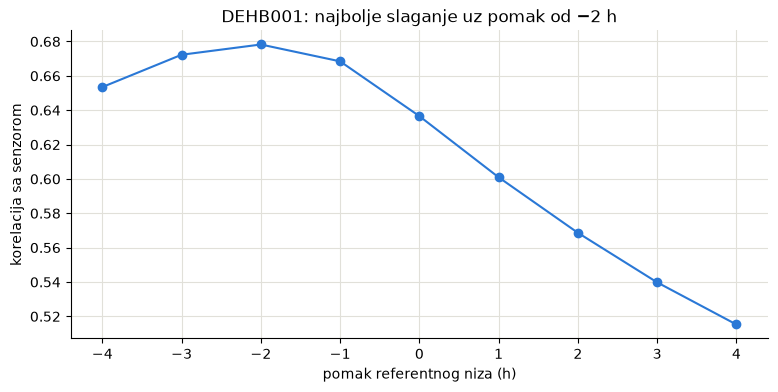

In [5]:
sens = pd.read_parquet(INTERIM / "sensors_hourly.parquet").set_index(["sensor_id", "time"])
ref = pd.read_parquet(INTERIM / "reference_hourly.parquet").set_index(["station_code", "time"])
s, r = sens.loc[86471], ref.loc["DEHB001"]
lagovi = range(-4, 5)
korelacije = []
for lag in lagovi:
    pomaknut = r["pm10_ref"].copy()
    pomaknut.index = pomaknut.index + pd.Timedelta(hours=lag)
    par = pd.concat([s["pm10_lc"], pomaknut], axis=1, join="inner").dropna()
    korelacije.append(par.iloc[:, 0].corr(par.iloc[:, 1]))
plt.plot(list(lagovi), korelacije, marker="o", color=BOJE["gbm_full"])
plt.xlabel("pomak referentnog niza (h)"); plt.ylabel("korelacija sa senzorom")
plt.title("DEHB001: najbolje slaganje uz pomak od −2 h"); plt.show()

Isti test otkriva i **neispravne parove**: ako senzor ni uz jedan pomak ne prati referencu (r < 0,3),
ili je pokvaren ili ne mjeri isti zrak. Takvih je 6 i isključeni su (`excluded_pairs.csv`).

In [6]:
pd.read_csv(INTERIM / "excluded_pairs.csv")

,sensor_id,station
0,80177,BETR702
1,29576,DESH053
2,22595,BETR834
3,90258,FR12042
4,17414,AT30603
5,16472,DEBE034


## 4. Koliko griješe nekorigirani senzori

Prvo osnovne mjere za sve sate zajedno:
- **R²**: koliki dio varijacije referentne vrijednosti senzor objašnjava (1 = savršeno; može biti i negativan
  kad je pogreška veća od same varijacije),
- **RMSE**: korijen srednje kvadratne pogreške u µg/m³,
- **bias**: prosječna razlika senzor − referenca.

In [7]:
def mjere(senzor, referenca):
    d = pd.concat([senzor, referenca], axis=1).dropna()
    x, y = d.iloc[:, 0], d.iloc[:, 1]
    return {"sati": len(d), "R2": 1 - ((x - y) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "RMSE": np.sqrt(((x - y) ** 2).mean()), "bias": (x - y).mean(), "omjer senzor/ref": x.mean() / y.mean()}

tab = pd.DataFrame({"PM2,5": mjere(m.pm25_lc, m.pm25_ref), "PM10": mjere(m.pm10_lc, m.pm10_ref)}).T
tab["sati"] = tab["sati"].astype(int)
tab

,sati,R2,RMSE,bias,omjer senzor/ref
"PM2,5",1102171,0.53,8.76,-4.38,0.60
PM10,1214489,-0.05,18.78,-4.31,0.76


Senzor u prosjeku pokazuje oko 40 % premalo PM2,5, a PM10 je još lošiji. Razlog za PM10 vidi se kad
podijelimo sate prema tome **koliko je zrak krupan**, mjereno referentnim omjerom PM2,5/PM10
(nizak omjer = puno krupnih čestica, tipično za prašinu):

In [8]:
d = m[(m.pm10_ref > 10) & (m.pm25_ref > 0)].dropna(subset=["pm10_lc"]).copy()
d["omjer_ref"] = d.pm25_ref / d.pm10_ref
d["razred"] = pd.cut(d.omjer_ref, [0, 0.3, 0.45, 0.6, 0.75, 0.9, 1.01])
tablica = d.groupby("razred", observed=True).apply(
    lambda g: pd.Series({"sati": len(g), "senzor vidi (% PM10)": 100 * (g.pm10_lc / g.pm10_ref).median()}))
tablica["sati"] = tablica["sati"].astype(int)
tablica

,sati,senzor vidi (% PM10)
razred,,
"(0.0, 0.3]",39665,24.37
"(0.3, 0.45]",133915,35.10
"(0.45, 0.6]",185426,47.33
"(0.6, 0.75]",178856,63.78
"(0.75, 0.9]",135307,88.72
"(0.9, 1.01]",27044,114.62


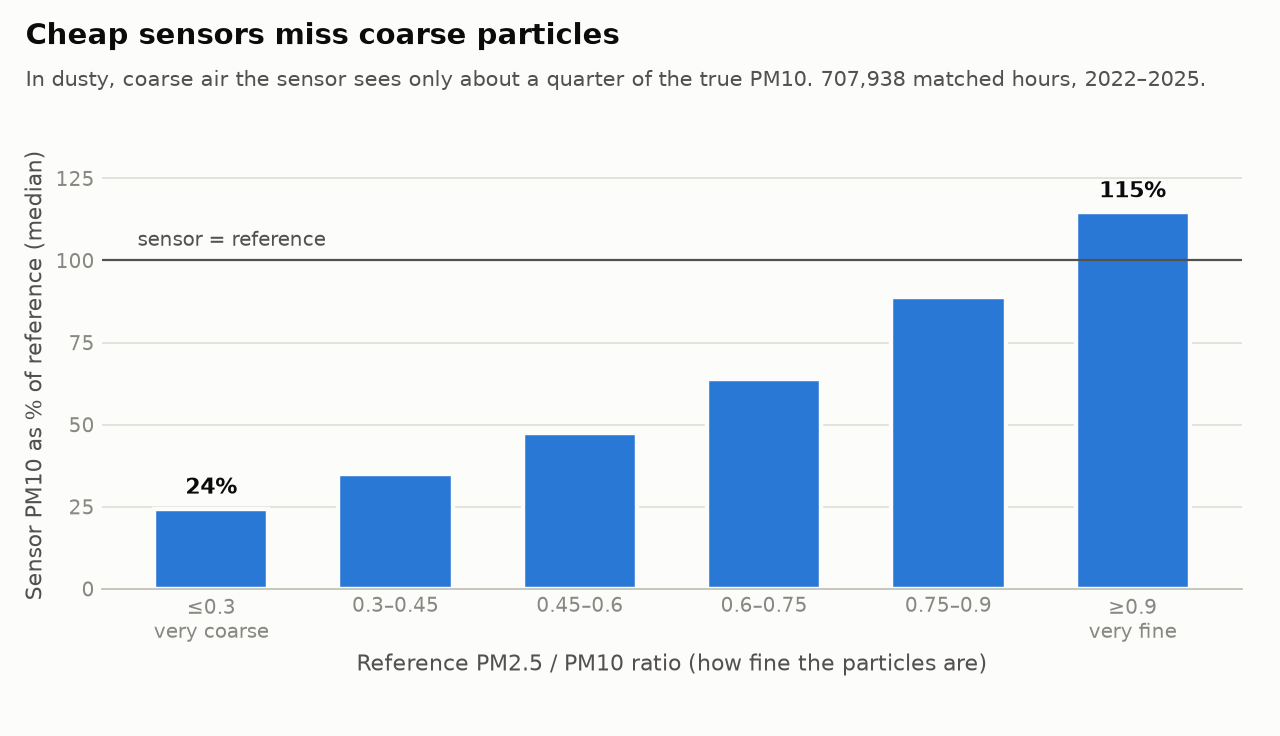

In [9]:
display(Image(filename=str(FIG / "coarse_underestimation_light.png"), width=750))

**Fizikalno objašnjenje:** SDS011 je optički brojač koji vidi uglavnom čestice manje od ~2,5 µm, a PM10 iz
tog broja procjenjuje uz pretpostavljenu raspodjelu veličina. Kad dominiraju krupne čestice (pustinjska prašina,
prašina s ceste), ta pretpostavka ne vrijedi i senzor drastično podcjenjuje PM10.

## 5. Utjecaj vlažnosti i κ-Köhler korekcija

Čestice upijaju vodu i pri visokoj vlažnosti narastu, pa ih optički senzor „vidi” kao veće i brojnije.
Pogledajmo prosječnu pogrešku nekorigiranog PM10 po razredima relativne vlažnosti (ERA5):

In [10]:
razredi = pd.cut(m.relative_humidity_2m, [0, 50, 60, 70, 80, 90, 95, 101], right=False)
(m.pm10_lc - m.pm10_ref).groupby(razredi, observed=True).agg(["mean", "count"]).rename(
    columns={"mean": "prosječna pogreška PM10 (µg/m³)", "count": "sati"})

,prosječna pogreška PM10 (µg/m³),sati
relative_humidity_2m,,
"[0, 50)",-12.10,109692
"[50, 60)",-9.70,110985
"[60, 70)",-8.06,161418
"[70, 80)",-5.93,223879
"[80, 90)",-2.93,304663
"[90, 95)",0.17,183172
"[95, 101)",5.44,120680


U suhom zraku senzor podcjenjuje, u vrlo vlažnom precjenjuje. Standardna fizikalna korekcija je
**κ-Köhlerova teorija higroskopnog rasta**: očitanje dijelimo faktorom rasta

```latex
f(a_w) = 1 + \frac{\kappa / 1{,}65}{1/a_w - 1}, \qquad a_w = \frac{RH}{100}
```

gdje je κ higroskopnost čestica (0 = ne upijaju vodu; ~0,2–0,6 za tipični urbani aerosol), a 1,65 gustoća
suhih čestica u g/cm³. κ smo birali na podacima za učenje: za PM10 ispao je 0,1–0,2, a za PM2,5 čak 0,
što znači da kod PM2,5 vlažnost nije glavni izvor pogreške.

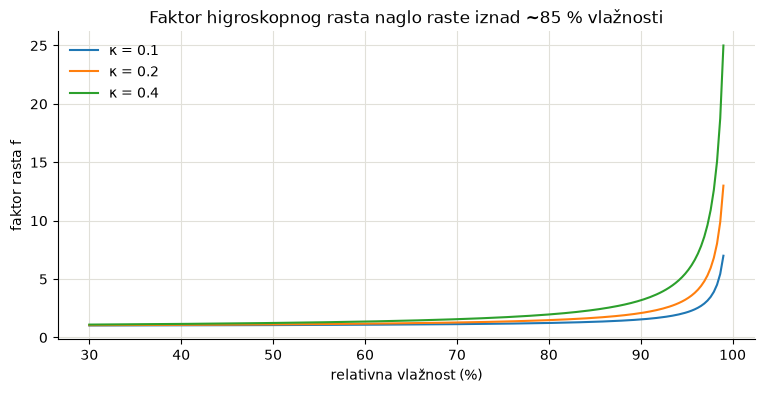

In [11]:
rh = np.linspace(30, 99, 200)
for kappa in (0.1, 0.2, 0.4):
    f = 1 + (kappa / 1.65) / (1 / (rh / 100) - 1)
    plt.plot(rh, f, label=f"κ = {kappa}")
plt.xlabel("relativna vlažnost (%)"); plt.ylabel("faktor rasta f"); plt.legend(frameon=False)
plt.title("Faktor higroskopnog rasta naglo raste iznad ~85 % vlažnosti"); plt.show()

## 6. Metode korekcije i strojno učenje

Usporedili smo sedam metoda, od najjednostavnije do najsloženije:

| Metoda | Opis |
|---|---|
| nekorigirano | vrijednost senzora |
| linearna | `ref = a + b × senzor` |
| linearna + vlažnost | dodaje relativnu vlažnost i temperaturu |
| κ-Köhler | dijeli s faktorom higroskopnog rasta pa linearno skalira |
| ML: senzor + meteorologija | LightGBM s oba kanala senzora, njihovim omjerom, ERA5 meteorologijom i dobom dana/godine |
| ML: CAMS + meteorologija, bez senzora | kontrolni model: pokazuje koliko CAMS postiže sam |
| ML: senzor + meteorologija + CAMS | sve gore plus CAMS prašina, AOD, CO i modelirani PM |

**LightGBM** (gradient boosting) gradi stotine malih stabala odlučivanja; svako ispravlja pogreške prethodnih.
Dobro hvata nelinearne odnose, npr. „kad je CAMS prašina visoka, a senzor vidi malo PM10, prava vrijednost je
mnogo viša”. Postavke modela:

In [12]:
import train_evaluate as te
print("Postavke LightGBM-a:", te.GBM_PARAMS)
print("Meteorološki ulazi:", te.WEATHER)
print("CAMS ulazi:", te.CAMS)

Postavke LightGBM-a: {'n_estimators': 600, 'learning_rate': 0.05, 'num_leaves': 63, 'min_child_samples': 200, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'verbose': -1}
Meteorološki ulazi: ['relative_humidity_2m', 'temperature_2m', 'dew_point_2m', 'boundary_layer_height', 'wind_speed_10m', 'precipitation', 'cloud_cover', 'surface_pressure']
CAMS ulazi: ['dust', 'aerosol_optical_depth', 'carbon_monoxide', 'pm10_cams', 'pm25_cams']


**Važno:** oznake epizoda (prašina, dim, vlažno) koriste referentni omjer PM2,5/PM10, ali **nikad nisu ulaz
modela**. Model vidi samo ono što bi imao i u stvarnoj primjeni: senzor, meteorologiju i CAMS.

## 7. Zašto validacija po postajama

Kad bismo sate nasumično dijelili na skup za učenje i skup za testiranje, model bi učio i testirao se na
**istim postajama** (čak na susjednim satima istog senzora). Rezultat bi izgledao bolje nego što jest,
jer bi model zapamtio posebnosti pojedinog senzora i lokacije.

Zato koristimo **unakrsnu validaciju grupiranu po postajama** (`GroupKFold`): svaka postaja je cijela ili u
skupu za učenje ili u skupu za testiranje. To odgovara stvarnom pitanju: *koliko dobro radi u novom gradu?*

Pokus na uzorku od 200 000 sati pokazuje razliku (traje oko minute):

In [13]:
from sklearn.model_selection import GroupKFold, KFold
import lightgbm as lgb

df = te.add_features(m).dropna(subset=["relative_humidity_2m", "dust", "pm10_lc", "pm10_ref"])
df["group"] = te.station_groups(df)
uzorak = df.sample(200_000, random_state=0).reset_index(drop=True)
znacajke = ["pm25_lc", "pm10_lc", "lc_ratio", "sensor_type"] + te.TIME + te.WEATHER + te.CAMS
params = {**te.GBM_PARAMS, "n_estimators": 200}

def rmse_cv(podjela, grupe=None):
    pogreske = []
    for tr, ts in podjela.split(uzorak, groups=grupe):
        g = lgb.LGBMRegressor(**params).fit(uzorak.loc[tr, znacajke], uzorak.loc[tr, "pm10_ref"])
        p = g.predict(uzorak.loc[ts, znacajke])
        pogreske.append(np.sqrt(np.mean((p - uzorak.loc[ts, "pm10_ref"]) ** 2)))
    return np.mean(pogreske)

nasumicno = rmse_cv(KFold(5, shuffle=True, random_state=0))
po_postajama = rmse_cv(GroupKFold(5), uzorak["group"])
print(f"RMSE PM10, nasumična podjela sati:   {nasumicno:.1f} µg/m³  (previše optimistično)")
print(f"RMSE PM10, podjela po postajama:     {po_postajama:.1f} µg/m³  (pošteno za novi grad)")

RMSE PM10, nasumična podjela sati:   8.9 µg/m³  (previše optimistično)
RMSE PM10, podjela po postajama:     10.9 µg/m³  (pošteno za novi grad)


Nasumična podjela daje primjetno manju pogrešku, ali to je iluzija: model je već „vidio” te postaje.
Svi rezultati projekta zato su iz podjele po postajama.

## 8. Rezultati

Pogreška (RMSE, µg/m³) svake metode na postajama koje model nije vidio, ukupno i po vrsti sati:

In [14]:
met = pd.read_csv(RESULTS / "metrics.csv")
nazivi = {"raw": "nekorigirano", "linear": "linearna", "linear_rh": "linearna + vlaga", "kohler": "κ-Köhler",
          "gbm_weather": "ML: senzor + meteo", "gbm_no_sensor": "ML: CAMS + meteo (bez senzora)",
          "gbm_full": "ML: senzor + meteo + CAMS"}
skupovi = {"all": "svi sati", "dust": "prašina", "smoke": "dim", "humid": "vlažno (≥ 85 %)", "normal": "ostalo"}
t = met.pivot_table(index=["target", "subset"], columns="method", values="rmse")[list(nazivi)]
t = t.rename(columns=nazivi).rename(index=skupovi, level=1).rename(index={"pm10": "PM10", "pm25": "PM2,5"}, level=0)
t.round(1)

method                  nekorigirano  linearna  linearna + vlaga  κ-Köhler  \
target subset                                                                
PM10   svi sati                18.80     15.20             15.00     14.20   
       prašina                 31.60     29.80             28.00     27.30   
       vlažno (≥ 85 %)         22.20     15.10             15.00     13.40   
       ostalo                  16.00     15.10             14.90     14.50   
       dim                     19.10     12.50             12.70     14.20   
PM2,5  svi sati                 8.80      7.80              7.70      7.80   
       prašina                 10.90      7.90              8.20      7.90   
       vlažno (≥ 85 %)          8.80      8.10              8.00      8.10   
       ostalo                   8.70      7.50              7.50      7.50   
       dim                     12.20     11.00             11.00     11.00   

method                  ML: senzor + meteo  ML: CAMS + meteo (bez senzora)  \
target subset                                                                
PM10   svi sati                      12.60                           12.90   
       prašina                       19.80                           17.20   
       vlažno (≥ 85 %)               11.70                           11.90   
       ostalo                        13.00                           13.50   
       dim                            9.70                           11.30   
PM2,5  svi sati                       7.60                            8.90   
       prašina                        5.90                            6.30   
       vlažno (≥ 85 %)                7.80                            8.60   
       ostalo                         7.50                            9.10   
       dim                            9.30                            8.70   

method                  ML: senzor + meteo + CAMS  
target subset                                      
PM10   svi sati                             11.60  
       prašina                              15.40  
       vlažno (≥ 85 %)                      10.70  
       ostalo                               12.20  
       dim                                   8.50  
PM2,5  svi sati                              6.60  
       prašina                               5.20  
       vlažno (≥ 85 %)                       6.70  
       ostalo                                6.60  
       dim                                   7.30

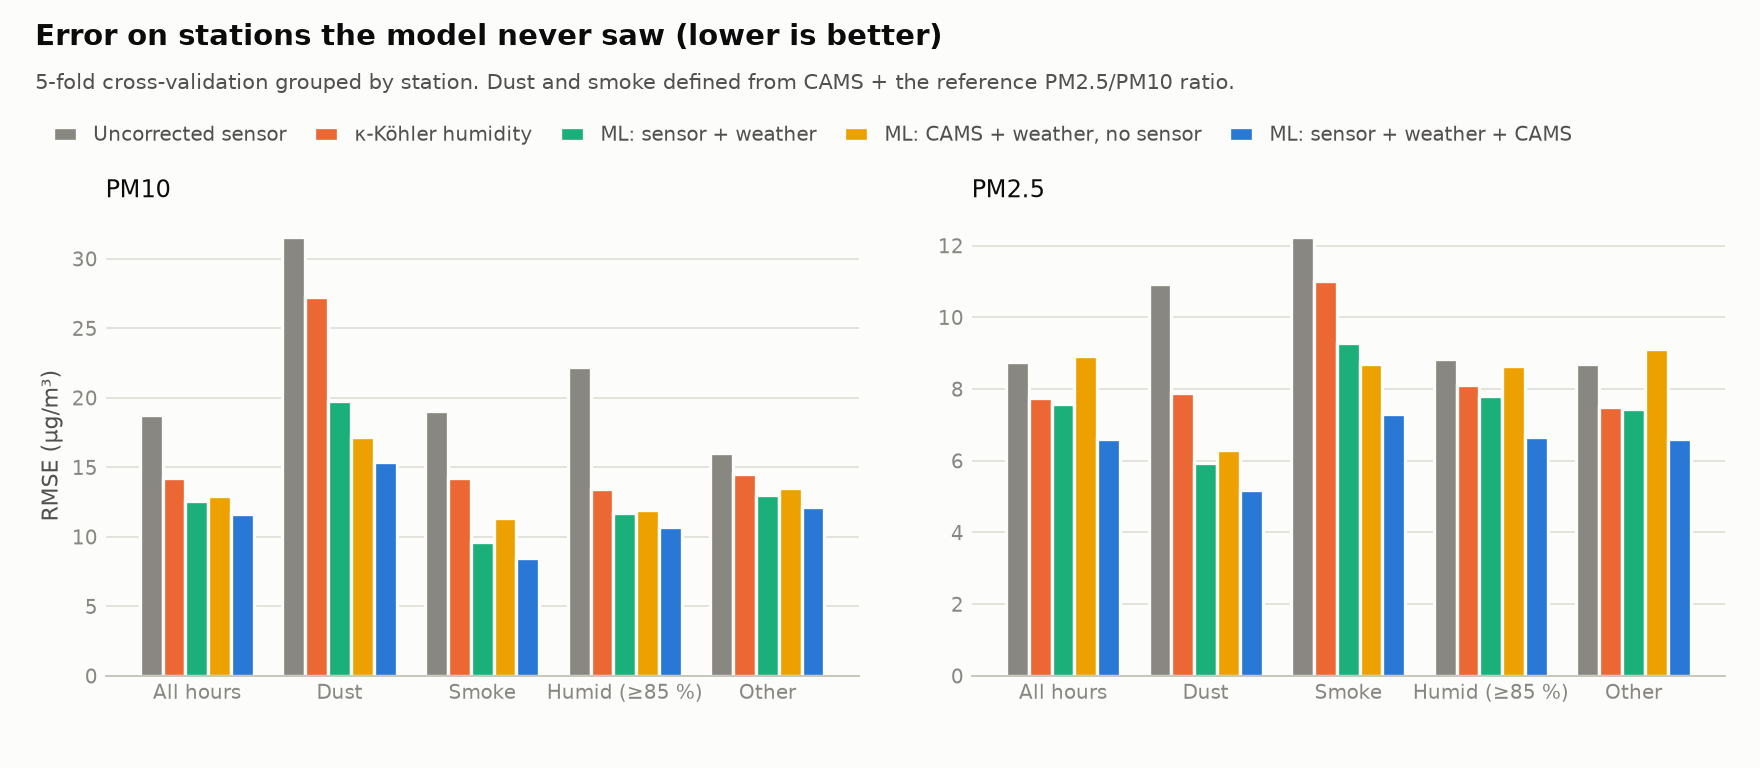

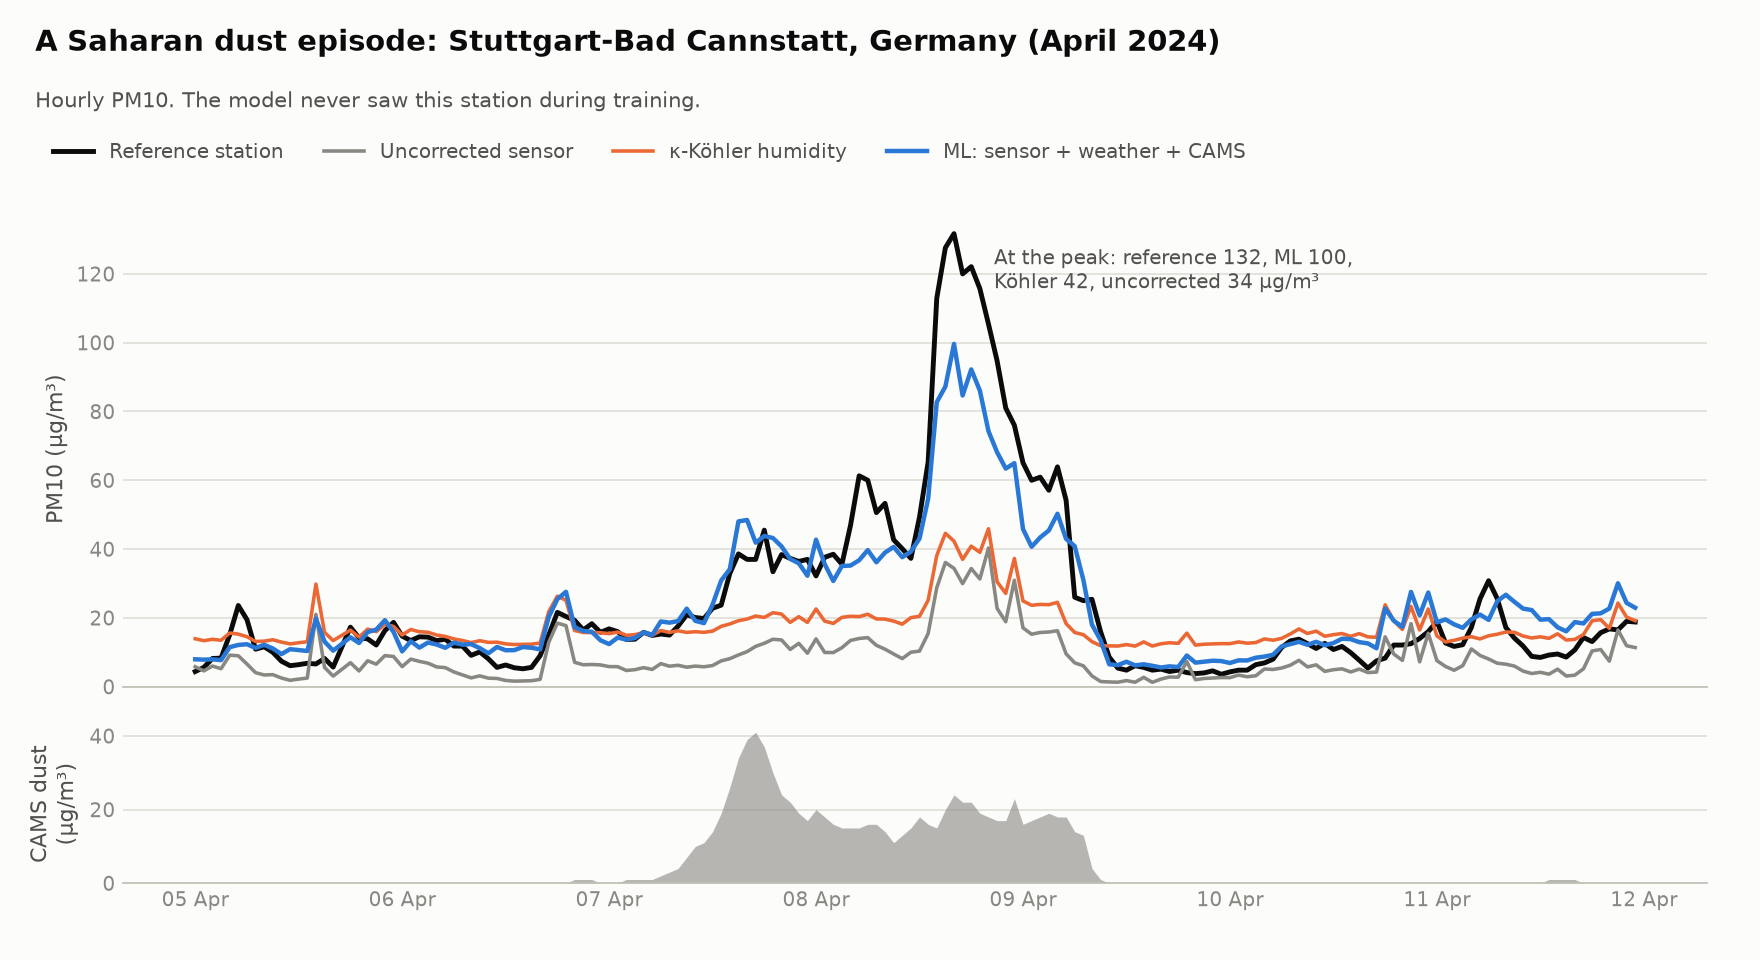

In [15]:
display(Image(filename=str(FIG / "rmse_by_condition_light.png"), width=900))
display(Image(filename=str(FIG / "dust_episode_light.png"), width=900))

**Kako čitati rezultate:**
- U epizodama prašine RMSE za PM10 pada s 31,6 (nekorigirano) na 27,3 (κ-Köhler) i na **15,4 µg/m³** s modelom
  koji koristi CAMS prašinu. Korekcija vlažnosti ne može nadoknaditi čestice koje senzor uopće ne vidi.
- Kontrolni model **bez senzora** lošiji je u svim uvjetima, posebno za PM2,5 (8,9 naspram 6,6 µg/m³):
  senzor nosi lokalnu informaciju koju CAMS na mreži od ~10 km nema.
- Rezultat za dim temelji se na samo 1295 sati i najmanje je siguran.

## 9. Što model zapravo koristi

Važnost značajki (*gain*: koliko svaka značajka ukupno smanjuje pogrešku u stablima) za PM10 model,
naučen na istom uzorku:

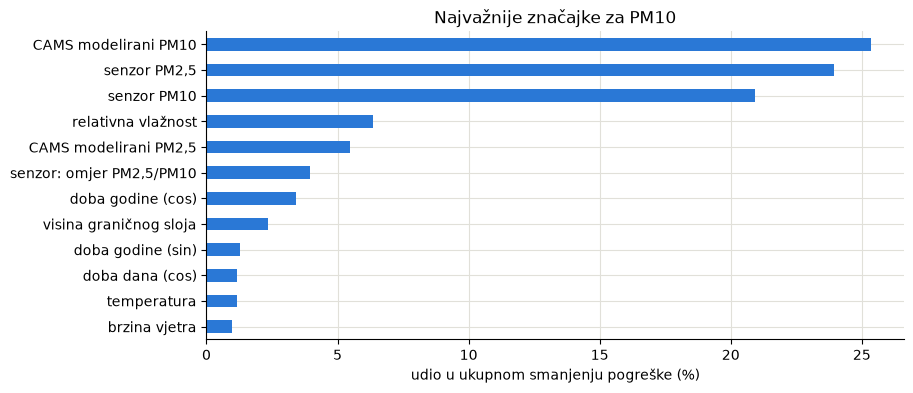

In [16]:
g = lgb.LGBMRegressor(**params, importance_type="gain").fit(uzorak[znacajke], uzorak["pm10_ref"])
nazivi_hr = {"pm10_cams": "CAMS modelirani PM10", "pm25_cams": "CAMS modelirani PM2,5", "pm25_lc": "senzor PM2,5",
             "pm10_lc": "senzor PM10", "lc_ratio": "senzor: omjer PM2,5/PM10", "relative_humidity_2m": "relativna vlažnost",
             "temperature_2m": "temperatura", "dew_point_2m": "točka rosišta", "boundary_layer_height": "visina graničnog sloja",
             "wind_speed_10m": "brzina vjetra", "precipitation": "oborina", "cloud_cover": "naoblaka",
             "surface_pressure": "tlak zraka", "dust": "CAMS prašina", "aerosol_optical_depth": "CAMS AOD",
             "carbon_monoxide": "CAMS CO", "sensor_type": "tip senzora", "hour_sin": "doba dana (sin)",
             "hour_cos": "doba dana (cos)", "doy_sin": "doba godine (sin)", "doy_cos": "doba godine (cos)"}
vaznost = pd.Series(g.feature_importances_, index=[nazivi_hr.get(z, z) for z in znacajke]).sort_values()
(vaznost / vaznost.sum() * 100).tail(12).plot.barh(color=BOJE["gbm_full"])
plt.xlabel("udio u ukupnom smanjenju pogreške (%)"); plt.title("Najvažnije značajke za PM10"); plt.show()

Najviše doprinose CAMS-ov modelirani PM10 i očitanja samog senzora (PM2,5 i PM10), a zatim relativna vlažnost.
Varijabla CAMS prašine u ukupnom poretku jedva se vidi jer su sati prašine samo 0,57 % podataka, a modelirani
PM10 već sadrži doprinos prašine. Njezina vrijednost vidi se upravo u tim satima: u epizodama prašine RMSE za PM10
pada s 19,8 (model bez CAMS-a) na 15,4 µg/m³ (model s CAMS-om). Važnost značajke u prosjeku nije isto što i
važnost u rijetkim, ali bitnim situacijama.

## 10. Ograničenja

- **Geografija:** većina parova je u Njemačkoj, Belgiji, Nizozemskoj i Poljskoj; hrvatskih parova nema.
- **Meteorologija na mreži:** ERA5 i CAMS (10–25 km), a ne vlažnost na samom senzoru.
- **Reanaliza, ne prognoza:** u stvarnom vremenu koristile bi se CAMS prognoze, nešto manje točne.
- **Epizode su aproksimacija** definirana iz CAMS-a i referentnog omjera PM2,5/PM10.
- **Senzori:** gotovo svi SDS011; popis aktivnih senzora iz studenog 2026.
- **Vrijeme:** validacija izdvaja postaje, ne godine.

## 11. Pitanja za vježbu

Pokušaj odgovoriti naglas, pa otvori odgovor.

<details><summary><b>Zašto ne biste jednostavno koristili CAMS umjesto senzora?</b></summary>

CAMS radi na mreži od ~10 km i ne vidi lokalne izvore (promet, ložišta, gradilišta). Kontrolni model samo s CAMS-om i
meteorologijom lošiji je u svim uvjetima; za PM2,5 RMSE 8,9 naspram 6,6 µg/m³ sa senzorom. Senzor i CAMS se nadopunjuju.
</details>

<details><summary><b>Zašto κ-Köhler ne pomaže u epizodama prašine?</b></summary>

Köhler ispravlja higroskopni rast, dakle pogrešku zbog vlage. U prašini je problem drugi: krupne mineralne čestice
koje optički senzor gotovo ne detektira. Nijedan faktor vlažnosti ne može vratiti čestice koje nisu izbrojane.
</details>

<details><summary><b>Kako znate da model ne vara, tj. da ne „vidi” referencu?</b></summary>

Referentne vrijednosti nikad nisu ulaz modela, ni izravno ni preko oznaka epizoda. Testiranje je na postajama
koje u učenju nisu sudjelovale, a senzori blizu dviju postaja drže se u istoj skupini da ne bi „procurili”.
</details>

<details><summary><b>Zašto su neke postaje dobile vremenski pomak?</b></summary>

Unakrsna korelacija pokazala je da se najbolje slažu uz pomak od 1–2 h, isti ljeti i zimi. To nije ljetno računanje
vremena nego drugačije označavanje sata kod tih postaja. Bez ispravka bismo uspoređivali pogrešne sate.
</details>

<details><summary><b>Što bi trebalo da se rezultat potvrdi za Hrvatsku?</b></summary>

Kolokacijska kampanja: nekoliko jeftinih senzora uz referentne instrumente (npr. na IMI-ju) kroz bar jednu sezonu
s epizodama saharske prašine, pa provjera modela na tim podacima bez ponovnog učenja.
</details>

<details><summary><b>Koliko je siguran rezultat za dim?</b></summary>

Najmanje od svih: samo 1295 sati, a definicija dima (CO iz CAMS-a + fini omjer + sezona) je aproksimacija.
Smjer rezultata je jasan, ali brojke treba uzeti s rezervom.
</details>

<details><summary><b>Zašto je PM2,5 κ ispao 0?</b></summary>

Na podacima za učenje dodavanje Köhlerovog faktora nije smanjilo pogrešku za PM2,5. Senzori PM2,5 sustavno
podcjenjuju (~40 %), pa je glavna pogreška razina, a ne vlaga; linearna korekcija to već ispravlja.
</details>